In [1]:
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as T
from torch.utils.data import DataLoader

In [2]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

In [3]:
train_set = datasets.CIFAR10(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

/opt/homebrew/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [4]:
train_loader = DataLoader(train_set, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False, num_workers=2)

In [5]:
len(train_loader)

391

## Выбрали ViT

In [6]:
import timm

In [ ]:
modelViT = timm.models.vision_transformer.VisionTransformer(
    img_size=32, patch_size=8, num_classes=10,
    embed_dim=64, depth=3, num_heads=4, mlp_ratio=2.0,
)
print(sum(p.numel() for p in modelViT.parameters()) / 1e6, "M params")  # ~0.1M

0.546186 M params


## Training loop

In [7]:
N_EPOCHS = 10
lr = 1e-3
device = 'cpu'

In [8]:
def one_epoch(loader, criterion, optimizer):
    modelViT.train()
    sumloss = 0
    n_cnt = 0
    for batch, labels in loader:
        batch, labels = batch.to(device), labels.to(device)
        optimizer.zero_grad()
        probs = modelViT(batch)
        loss = criterion(probs, labels)
        loss.backward()
        optimizer.step()
        sumloss += loss.item() * len(batch)
        n_cnt += len(batch)
    return sumloss/ n_cnt

In [ ]:
modelViT = timm.models.vision_transformer.VisionTransformer(
    img_size=32, patch_size=8, num_classes=10,
    embed_dim=64, depth=3, num_heads=4, mlp_ratio=2.0,
)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(modelViT.parameters(), lr, weight_decay=0.1)
print(sum(p.numel() for p in modelViT.parameters()) / 1e6, "M params")  # ~0.1M

epoch_losses = []
for epoch in range(N_EPOCHS):
    loss = one_epoch(train_loader, criterion, optimizer)
    epoch_losses.append(loss)

0.114698 M params


In [62]:
epoch_losses

[1.8353327869033813,
 1.5784953263473511,
 1.4295007335662842,
 1.3467943894195558,
 1.2794057245635986,
 1.22070126953125,
 1.174272186088562,
 1.1232476517868042,
 1.0816233686828614,
 1.0481094607162476]

In [63]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Adam w/o lr scheduler')

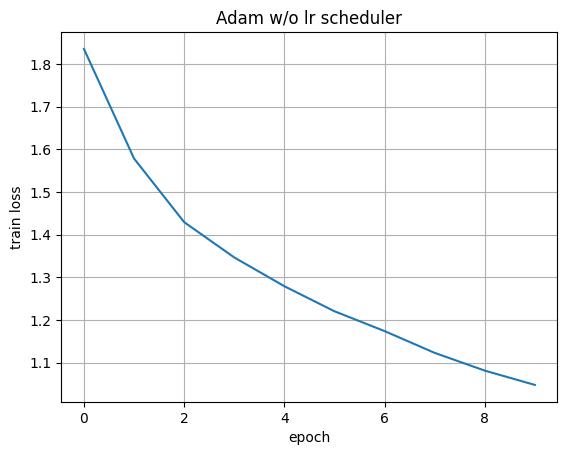

In [67]:
plt.plot(torch.arange(N_EPOCHS), epoch_losses)
plt.grid(True)
plt.xlabel('epoch')
plt.ylabel('train loss')
plt.title('Adam w/o lr scheduler')

## SPlus implementation

In [9]:
import splus

In [12]:
modelViT = timm.models.vision_transformer.VisionTransformer(
    img_size=32, patch_size=8, num_classes=10,
    embed_dim=64, depth=3, num_heads=4, mlp_ratio=2.0,
)
criterion = nn.CrossEntropyLoss()
optimizer = splus.SPlus(modelViT.parameters(), lr = 0.1)
print(sum(p.numel() for p in modelViT.parameters()) / 1e6, "M params")  # ~0.1M

epoch_losses = []
for epoch in range(10):
    loss = one_epoch(train_loader, criterion, optimizer)
    epoch_losses.append(loss)

0.114698 M params


In [13]:
epoch_losses

[1.7620725876617431,
 1.4315168854522704,
 1.26024910987854,
 1.1532857585334777,
 1.0699723769760132,
 1.0036865591049193,
 0.9497925326538086,
 0.9040544129562378,
 0.8584829738998413,
 0.8175264434432984]

In [15]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'SPlus w/o lr scheduler')

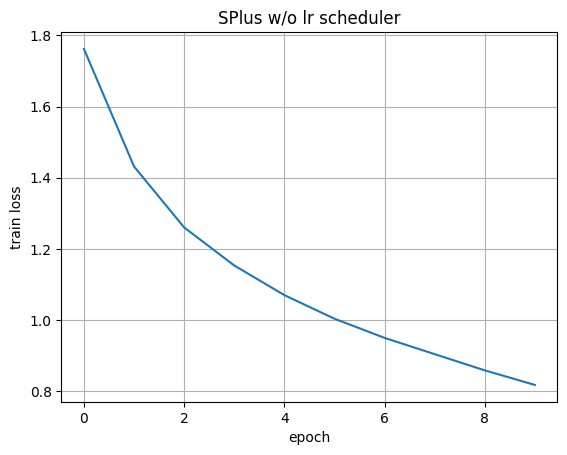

In [16]:
plt.plot(torch.arange(N_EPOCHS), epoch_losses)
plt.grid(True)
plt.xlabel('epoch')
plt.ylabel('train loss')
plt.title('SPlus w/o lr scheduler')

In [ ]:
#model: ViT ~5M params
#scheduler: CosineScheduler for Adam, AdamW
#optimizer: Adam, AdamW, SPlus
#Нужно также подобрать оптимальный learning rate для Adam, AdamW и SPlus
#Нужно сохранить все лоссы на каждой эпохи для каждого эксперимента. 
#Также сохранить validation loss (то есть просто протестить в самом конце на test_loader в нашем случае) для каждого эксперимента.